# Drone vs Bird


## Setup

In [1]:
import os, glob, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 12
CLASSES = ['bird', 'drone']             # bird = 0, drone = 1
FIG_DIR, MODEL_DIR = 'figures', 'models'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Download the Dataset


In [2]:
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!kaggle datasets download -d muhammadsaoodsarwar/drone-vs-bird
!unzip -q -o drone-vs-bird.zip -d dataset/

Dataset URL: https://www.kaggle.com/datasets/muhammadsaoodsarwar/drone-vs-bird
License(s): apache-2.0
100% 1.59G/1.59G [00:21<00:00, 80.3MB/s]



## Step 2: Validate and Resize Images
Every image is opened once, converted to RGB and resized to 224×224. Unreadable files are skipped and reported. Resizing once up front also makes each training epoch much faster.

In [3]:
def find_data_dir(root='dataset'):
    for dirpath, dirnames, _ in os.walk(root):
        if {'bird', 'drone'} <= {d.lower() for d in dirnames}:
            return dirpath
    raise FileNotFoundError('Could not find bird/ and drone/ folders under ' + root)

DATA_DIR = find_data_dir()
RESIZED_DIR = 'resized'
records, skipped = [], []

for label in CLASSES:
    src_folder = next(os.path.join(DATA_DIR, d) for d in os.listdir(DATA_DIR) if d.lower() == label)
    dst_folder = os.path.join(RESIZED_DIR, label)
    os.makedirs(dst_folder, exist_ok=True)
    for i, path in enumerate(sorted(glob.glob(os.path.join(src_folder, '*')))):
        try:
            with Image.open(path) as im:
                im = im.convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
                out_path = os.path.join(dst_folder, f'{label}_{i:05d}.jpg')
                im.save(out_path, quality=95)
            records.append({'filepath': out_path, 'label': label, 'source': os.path.basename(path)})
        except Exception:
            skipped.append(path)

df = pd.DataFrame(records)
print(df['label'].value_counts().to_string())
print('Unreadable files skipped:', len(skipped))

label
drone    2499
bird     1607
Unreadable files skipped: 0


## Step 3: Stratified Train / Validation / Test Split (70 / 15 / 15)

In [4]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

split_summary = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'validation': val_df['label'].value_counts(),
    'test': test_df['label'].value_counts(),
}).loc[CLASSES]
split_summary.loc['total'] = split_summary.sum()
print(split_summary.to_string())

MAJORITY_BASELINE = test_df['label'].value_counts(normalize=True).max()
print(f'\nMajority-class baseline accuracy on the test set: {MAJORITY_BASELINE:.1%}')

# Class weights so the minority class (bird) is not ignored
w = compute_class_weight('balanced', classes=np.array(CLASSES), y=train_df['label'])
CLASS_WEIGHT = {i: float(v) for i, v in enumerate(w)}
print('Class weights:', CLASS_WEIGHT)

       train  validation  test
label                         
bird    1125         241   241
drone   1749         375   375
total   2874         616   616

Majority-class baseline accuracy on the test set: 60.9%
Class weights: {0: 1.2773333333333334, 1: 0.8216123499142367}


## Step 4: Data Generators with Model-Specific Preprocessing
Augmentation (rotation, flip, zoom) is applied to the training set only. Validation and test images are only preprocessed.

In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

FLOW_ARGS = dict(x_col='filepath', y_col='label', target_size=IMG_SIZE, classes=CLASSES,
                 class_mode='binary', batch_size=BATCH_SIZE)

def train_val_generators(preprocess_fn):
    train_aug = ImageDataGenerator(preprocessing_function=preprocess_fn,
                                   rotation_range=20, horizontal_flip=True, zoom_range=0.2)
    plain = ImageDataGenerator(preprocessing_function=preprocess_fn)
    train = train_aug.flow_from_dataframe(train_df, shuffle=True, seed=SEED, **FLOW_ARGS)
    val = plain.flow_from_dataframe(val_df, shuffle=False, **FLOW_ARGS)
    return train, val

def eval_generator(frame, preprocess_fn):
    plain = ImageDataGenerator(preprocessing_function=preprocess_fn)
    return plain.flow_from_dataframe(frame, shuffle=False, **FLOW_ARGS)

## Step 5: Define the Four Models
The Custom CNN uses the best settings from the  grid search (learning rate 0.0001, dropout 0.3). The three transfer learning models start from ImageNet weights with a frozen base.

In [6]:
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2, ResNet50, VGG16, mobilenet_v2, resnet50, vgg16

def rescale(x):
    return x / 255.0

def build_custom_cnn(learning_rate=1e-4, dropout=0.3):
    model = models.Sequential([layers.Input(shape=IMG_SIZE + (3,))])
    for filters in [32, 64, 128, 128]:
        model.add(layers.Conv2D(filters, (3, 3), activation='relu'))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D(2, 2))
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=optimizers.Adam(learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model, None

def build_transfer(base_cls, learning_rate=1e-3, dropout=0.5):
    base = base_cls(weights='imagenet', include_top=False, input_shape=IMG_SIZE + (3,))
    base.trainable = False
    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=optimizers.Adam(learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model, base

# name: (builder, preprocessing function, preprocessing name used by the demo app)
MODELS = {
    'Custom CNN':  (build_custom_cnn,                  rescale,                      'rescale'),
    'MobileNetV2': (lambda: build_transfer(MobileNetV2), mobilenet_v2.preprocess_input, 'mobilenet_v2'),
    'ResNet50':    (lambda: build_transfer(ResNet50),    resnet50.preprocess_input,     'resnet50'),
    'VGG16':       (lambda: build_transfer(VGG16),       vgg16.preprocess_input,        'vgg16'),
}

## Step 6: Train All Models
Each model trains for up to 12 epochs. Early stopping watches the validation loss and restores the best weights.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

def slug(name):
    return name.lower().replace(' ', '_').replace('(', '').replace(')', '')

def fit(model, name, train_gen, val_gen, epochs, patience=4):
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
        ModelCheckpoint(os.path.join(MODEL_DIR, slug(name) + '.keras'), monitor='val_loss', save_best_only=True),
    ]
    return model.fit(train_gen, validation_data=val_gen, epochs=epochs,
                     class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=1)

histories, trained = {}, {}
for name, (builder, preprocess_fn, prep_name) in MODELS.items():
    print(f'\n===== Training {name} =====')
    tf.keras.utils.set_random_seed(SEED)
    train_gen, val_gen = train_val_generators(preprocess_fn)
    model, base = builder()
    histories[name] = fit(model, name, train_gen, val_gen, EPOCHS).history
    trained[name] = dict(model=model, base=base, preprocess=preprocess_fn, prep_name=prep_name)


===== Training Custom CNN =====
Found 2874 validated image filenames belonging to 2 classes.
Found 616 validated image filenames belonging to 2 classes.
Epoch 1/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 80s 702ms/step - accuracy: 0.8566 - loss: 0.4892 - val_accuracy: 0.6088 - val_loss: 1.8373
Epoch 2/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 47s 523ms/step - accuracy: 0.9248 - loss: 0.2167 - val_accuracy: 0.6088 - val_loss: 1.8857
Epoch 3/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 44s 493ms/step - accuracy: 0.9408 - loss: 0.1670 - val_accuracy: 0.6088 - val_loss: 2.7510
Epoch 4/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 48s 536ms/step - accuracy: 0.9499 - loss: 0.1402 - val_accuracy: 0.7273 - val_loss: 0.7345
Epoch 5/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 45s 502ms/step - accuracy: 0.9523 - loss: 0.1413 - val_accuracy: 0.8474 - val_loss: 0.4628
Epoch 6/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 46s 514ms/step - accuracy: 0.9562 - loss: 0.1247 - val_accuracy: 0.8912 - val_loss: 0.2909
Epoch 7/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 46s 515ms/step - accuracy: 0.9642 

## Step 7: Evaluate on Validation and Test Sets

In [8]:
def predict_split(model, frame, preprocess_fn):
    gen = eval_generator(frame, preprocess_fn)
    probs = model.predict(gen, verbose=0).ravel()
    return gen.classes, probs

def metrics_row(y_true, probs):
    y_pred = (probs >= 0.5).astype(int)
    _, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Bird recall': recall[0],
        'Drone recall': recall[1],
        'Macro F1': f1.mean(),
        'ROC-AUC': roc_auc_score(y_true, probs),
    }

rows, test_preds = [], {}

def evaluate(name):
    m = trained[name]
    yv, pv = predict_split(m['model'], val_df, m['preprocess'])
    yt, pt = predict_split(m['model'], test_df, m['preprocess'])
    test_preds[name] = (yt, pt)
    val_f1 = metrics_row(yv, pv)['Macro F1']
    rows.append({'Model': name, 'Val Macro F1': val_f1, **metrics_row(yt, pt)})
    print(f'\n===== {name} (test set) =====')
    print(classification_report(yt, (pt >= 0.5).astype(int), target_names=['Bird', 'Drone'], digits=3, zero_division=0))

for name in MODELS:
    evaluate(name)

Found 616 validated image filenames belonging to 2 classes.
Found 616 validated image filenames belonging to 2 classes.

===== Custom CNN (test set) =====
              precision    recall  f1-score   support

        Bird      0.904     0.942     0.923       241
       Drone      0.962     0.936     0.949       375

    accuracy                          0.938       616
   macro avg      0.933     0.939     0.936       616
weighted avg      0.939     0.938     0.939       616

Found 616 validated image filenames belonging to 2 classes.
Found 616 validated image filenames belonging to 2 classes.

===== MobileNetV2 (test set) =====
              precision    recall  f1-score   support

        Bird      0.948     0.983     0.965       241
       Drone      0.989     0.965     0.977       375

    accuracy                          0.972       616
   macro avg      0.969     0.974     0.971       616
weighted avg      0.973     0.972     0.972       616

Found 616 validated image filenames

## Step 8: Fine-Tune MobileNetV2
Unfreeze the last 30 layers of MobileNetV2 (Batch Normalization layers stay frozen) and continue training with a small learning rate.

In [9]:
base_name, ft_name = 'MobileNetV2', 'MobileNetV2 (fine-tuned)'

# Work on a copy so the frozen MobileNetV2 results above stay unchanged
tf.keras.utils.set_random_seed(SEED)
ft_model, ft_base = build_transfer(MobileNetV2)
ft_model.set_weights(trained[base_name]['model'].get_weights())

ft_base.trainable = True
for layer in ft_base.layers[:-30]:
    layer.trainable = False
for layer in ft_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

ft_model.compile(optimizer=optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=['accuracy'])
train_gen, val_gen = train_val_generators(mobilenet_v2.preprocess_input)
histories[ft_name] = fit(ft_model, ft_name, train_gen, val_gen, epochs=8, patience=3).history
trained[ft_name] = dict(model=ft_model, base=ft_base, preprocess=mobilenet_v2.preprocess_input, prep_name='mobilenet_v2')
evaluate(ft_name)

Found 2874 validated image filenames belonging to 2 classes.
Found 616 validated image filenames belonging to 2 classes.
Epoch 1/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 67s 599ms/step - accuracy: 0.9781 - loss: 0.0720 - val_accuracy: 0.9756 - val_loss: 0.0526
Epoch 2/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 42s 463ms/step - accuracy: 0.9871 - loss: 0.0478 - val_accuracy: 0.9789 - val_loss: 0.0592
Epoch 3/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 39s 433ms/step - accuracy: 0.9868 - loss: 0.0397 - val_accuracy: 0.9773 - val_loss: 0.0672
Epoch 4/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 43s 461ms/step - accuracy: 0.9885 - loss: 0.0332 - val_accuracy: 0.9854 - val_loss: 0.0333
Epoch 5/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 42s 463ms/step - accuracy: 0.9941 - loss: 0.0295 - val_accuracy: 0.9821 - val_loss: 0.0299
Epoch 6/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 41s 455ms/step - accuracy: 0.9889 - loss: 0.0332 - val_accuracy: 0.9870 - val_loss: 0.0315
Epoch 7/8
90/90 ━━━━━━━━━━━━━━━━━━━━ 41s 458ms/step - accuracy: 0.9948 - loss: 0.0190 - val_accuracy: 0.9886 - 

## Step 9: Results Summary
Models are ranked by **validation** macro F1. The test columns are reported once, after model selection.

In [10]:
results = pd.DataFrame(rows).set_index('Model').sort_values('Val Macro F1', ascending=False)
results.to_csv(os.path.join(FIG_DIR, 'results.csv'))
print(f'Majority-class baseline (always predict "drone"): {MAJORITY_BASELINE:.1%} accuracy\n')
print((results * 100).round(1).to_string())

BEST = results.index[0]
print(f'\nBest model on validation: {BEST}')

Majority-class baseline (always predict "drone"): 60.9% accuracy

                          Val Macro F1  Accuracy  Bird recall  Drone recall  Macro F1  ROC-AUC
Model                                                                                         
MobileNetV2 (fine-tuned)          98.8      99.0         99.6          98.7      99.0     99.9
ResNet50                          98.5      99.4         99.6          99.2      99.3     99.7
MobileNetV2                       98.0      97.2         98.3          96.5      97.1     99.7
VGG16                             96.3      97.6         98.8          96.8      97.5     99.5
Custom CNN                        94.9      93.8         94.2          93.6      93.6     98.4

Best model on validation: MobileNetV2 (fine-tuned)


## Step 10: Figures

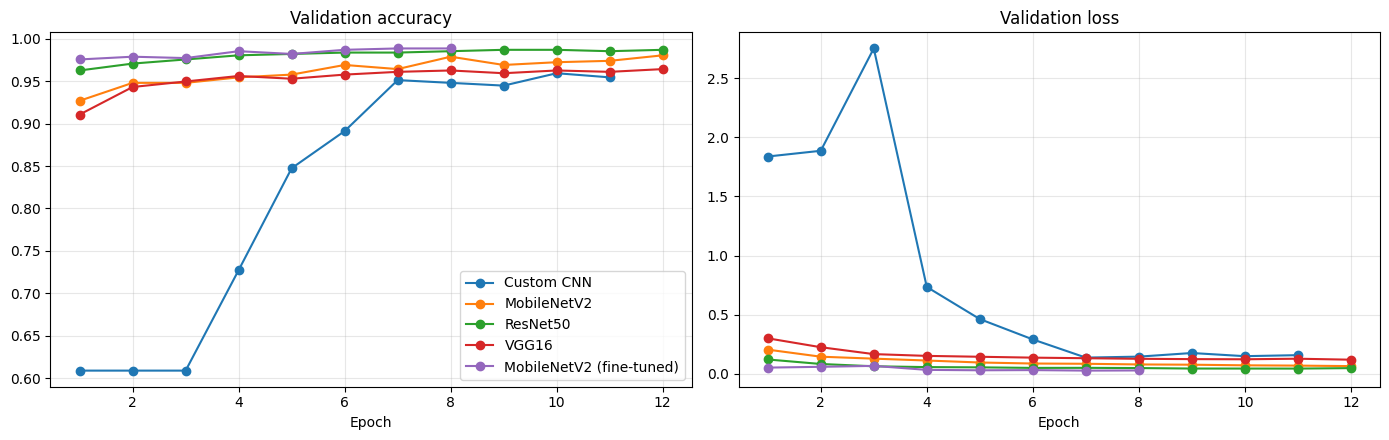

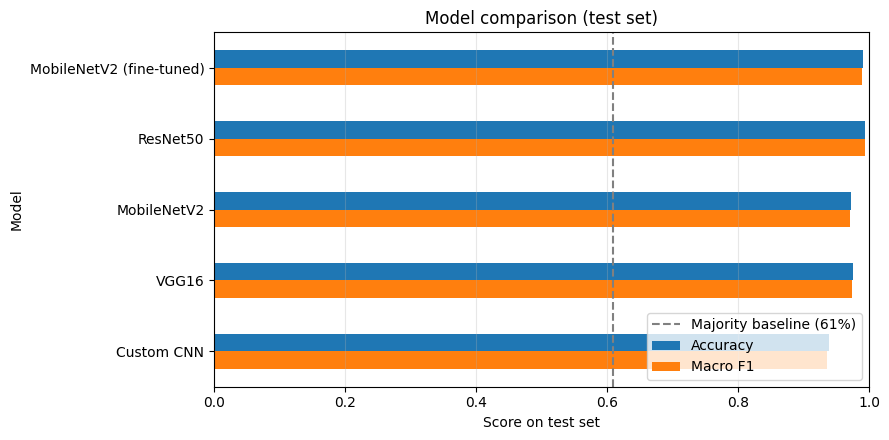

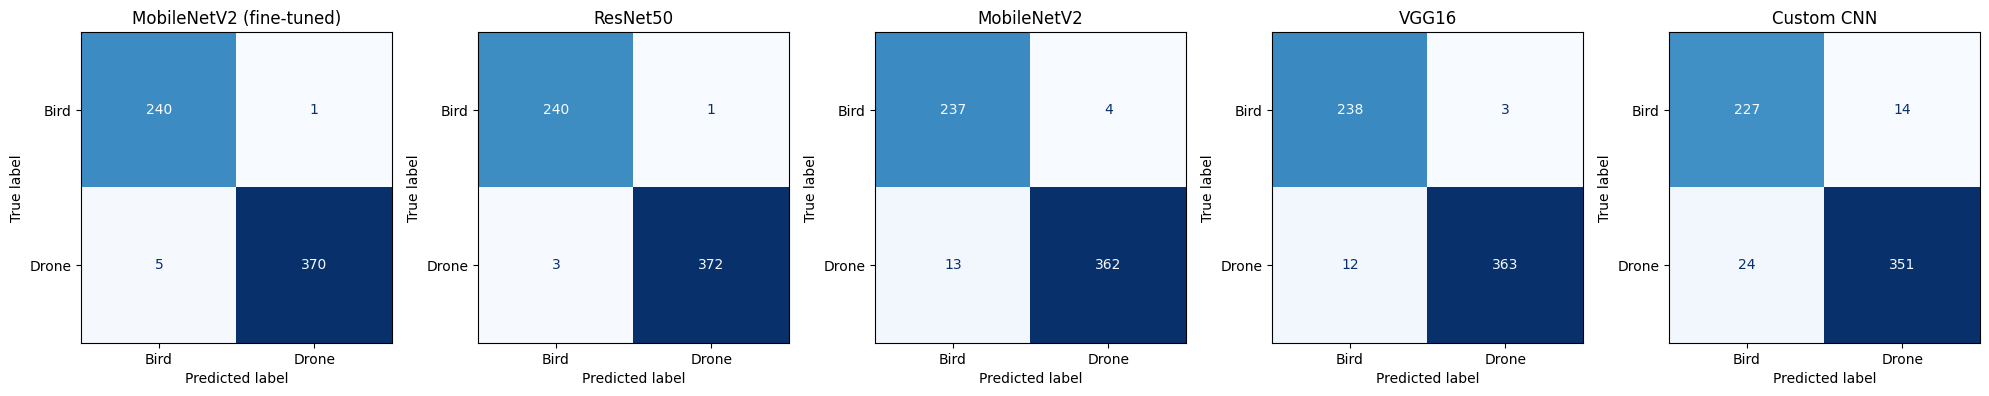

In [11]:
# 1) Validation curves for every model
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in histories.items():
    epochs = range(1, len(h['val_accuracy']) + 1)
    axes[0].plot(epochs, h['val_accuracy'], marker='o', label=name)
    axes[1].plot(epochs, h['val_loss'], marker='o', label=name)
axes[0].set_title('Validation accuracy'); axes[1].set_title('Validation loss')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight'); plt.show()

# 2) Test metrics compared with the majority baseline
ax = results[['Accuracy', 'Macro F1']].plot.barh(figsize=(9, 4.5), xlim=(0, 1))
ax.axvline(MAJORITY_BASELINE, color='gray', linestyle='--', label=f'Majority baseline ({MAJORITY_BASELINE:.0%})')
ax.invert_yaxis(); ax.set_xlabel('Score on test set'); ax.legend(loc='lower right'); ax.grid(axis='x', alpha=0.3)
plt.title('Model comparison (test set)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'model_comparison.png'), dpi=150, bbox_inches='tight'); plt.show()

# 3) Confusion matrices on the test set
names = list(results.index)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4))
for ax, name in zip(np.atleast_1d(axes), names):
    yt, pt = test_preds[name]
    cm = confusion_matrix(yt, (pt >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Bird', 'Drone']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'confusion_matrices.png'), dpi=150, bbox_inches='tight'); plt.show()

## Step 11: Error Analysis
Which test images does the best model get wrong?

MobileNetV2 (fine-tuned): 6 of 616 test images misclassified


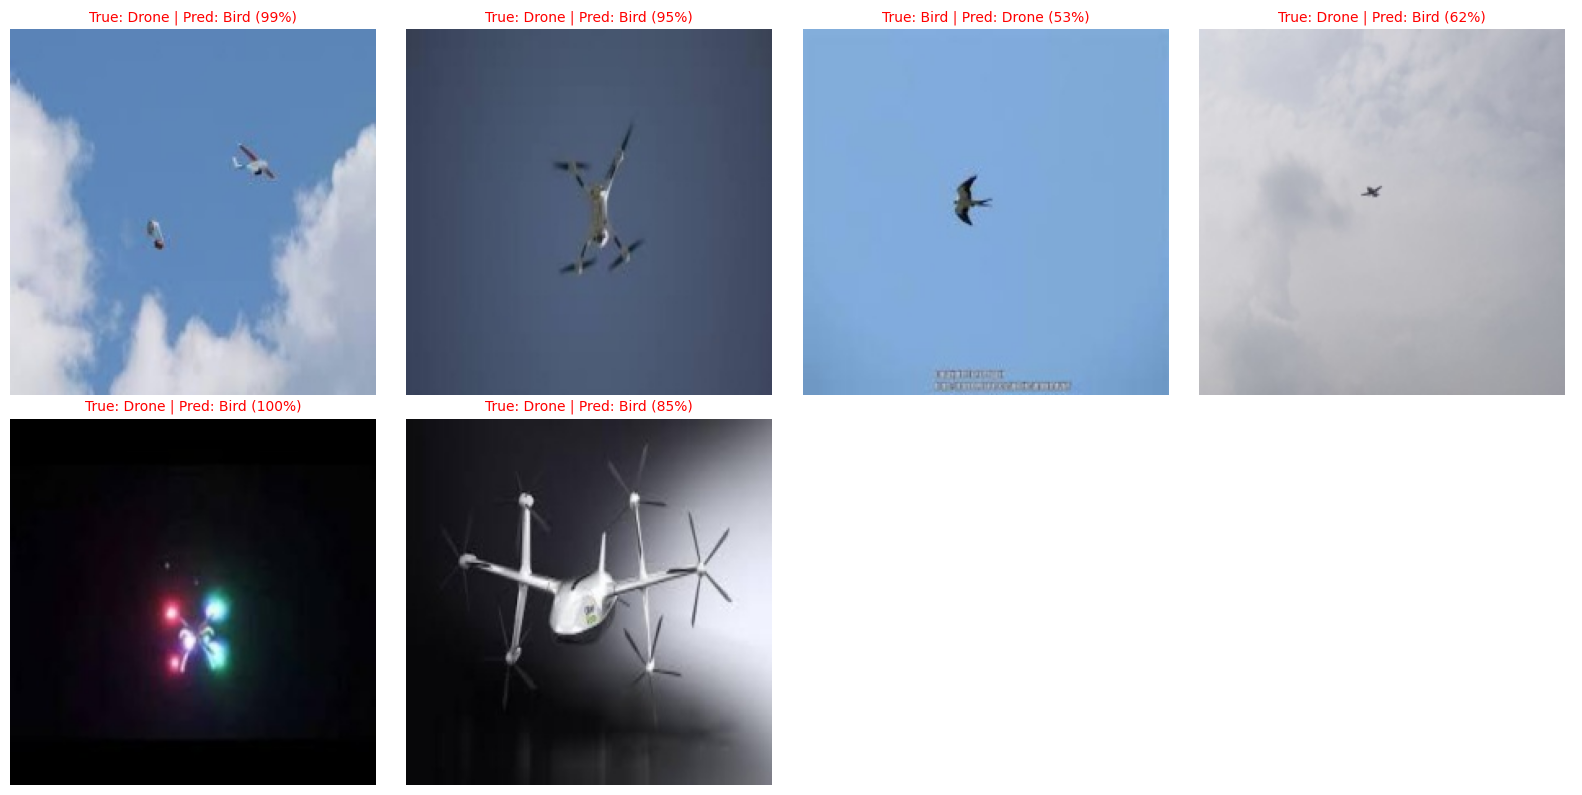

In [12]:
yt, pt = test_preds[BEST]
wrong = np.where((pt >= 0.5).astype(int) != yt)[0]
print(f'{BEST}: {len(wrong)} of {len(yt)} test images misclassified')

show = wrong[:8]
if len(show):
    cols = 4
    rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 4 * rows_n))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, i in zip(np.ravel(axes), show):
        ax.imshow(Image.open(test_df.iloc[i]['filepath']))
        true_lbl = CLASSES[yt[i]].title()
        pred_lbl = CLASSES[int(pt[i] >= 0.5)].title()
        conf = pt[i] if pt[i] >= 0.5 else 1 - pt[i]
        ax.set_title(f'True: {true_lbl} | Pred: {pred_lbl} ({conf:.0%})', color='red', fontsize=10)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'misclassified.png'), dpi=150, bbox_inches='tight'); plt.show()

## Step 12: Save the Best Model and Download the Outputs
The saved model and its info file are used by the demo app.

In [13]:
best = trained[BEST]
best['model'].save(os.path.join(MODEL_DIR, 'best_model.keras'))
with open(os.path.join(MODEL_DIR, 'best_model_info.json'), 'w') as f:
    json.dump({'model': BEST, 'preprocessing': best['prep_name'], 'classes': CLASSES,
               'image_size': list(IMG_SIZE), 'tensorflow': tf.__version__}, f, indent=2)
print('Saved', BEST)

!zip -q -r v2_outputs.zip figures models/best_model.keras models/best_model_info.json
from google.colab import files
files.download('v2_outputs.zip')

Saved MobileNetV2 (fine-tuned)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test images: 616
Byte-identical copies in training set: 78
Visually near-identical to a training image: 325

MobileNetV2 (fine-tuned) accuracy, full test set:          99.0%
MobileNetV2 (fine-tuned) accuracy, without exact copies:   98.9%  (538 images)
MobileNetV2 (fine-tuned) accuracy, without near-identical: 98.3%  (291 images)


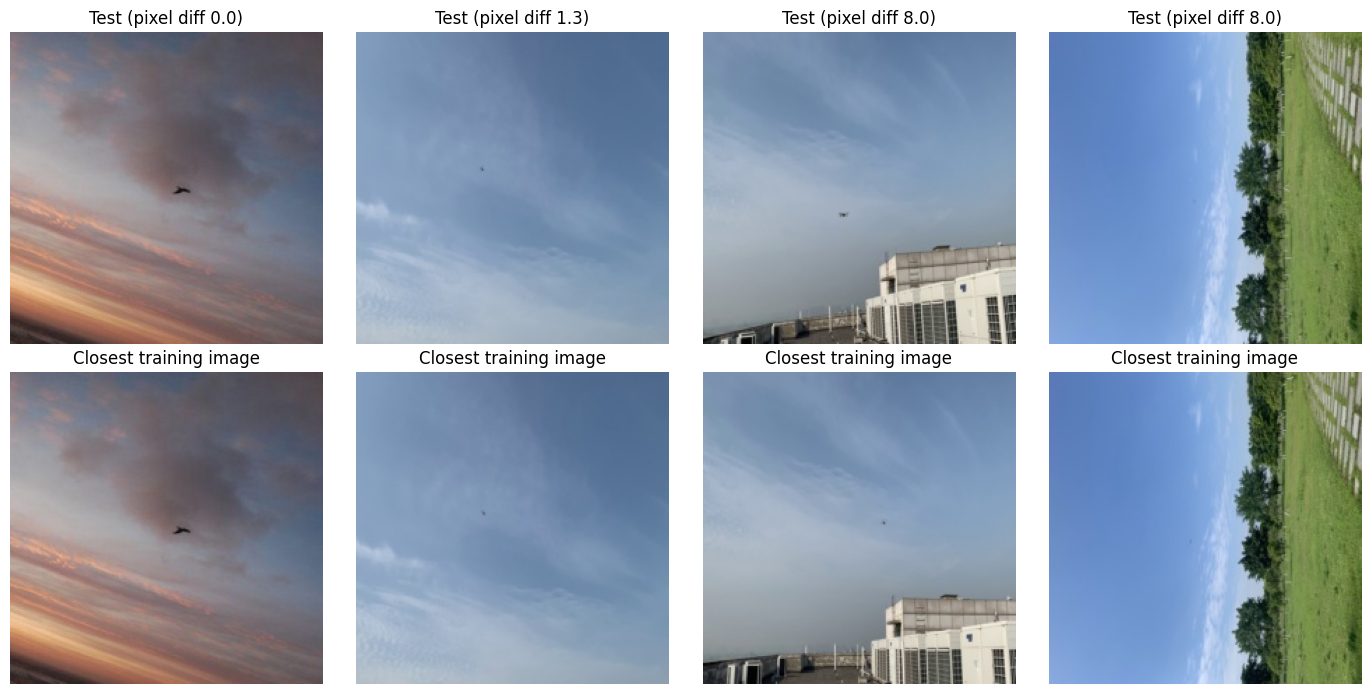

In [16]:
# Step 13: Data leakage check - are test images duplicated in the training set?
import hashlib

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def ahash(path, size=16):
    img = Image.open(path).convert('L').resize((size, size), Image.BILINEAR)
    a = np.asarray(img, dtype=np.float32)
    return (a > a.mean()).astype(np.float32).ravel()

def small(path, size=64):
    return np.asarray(Image.open(path).convert('RGB').resize((size, size), Image.BILINEAR), dtype=np.float32)

# Closest training image for every test image (perceptual hash)
train_h = np.stack([ahash(p) for p in train_df['filepath']])
test_h = np.stack([ahash(p) for p in test_df['filepath']])
dist = test_h.sum(1)[:, None] + train_h.sum(1)[None, :] - 2 * test_h @ train_h.T
nearest = dist.argmin(axis=1)

# 1) Byte-identical copies
train_md5 = set(md5(p) for p in train_df['filepath'])
exact = np.array([md5(p) in train_md5 for p in test_df['filepath']])

# 2) Visually near-identical (average pixel difference below 8 of 255)
pix_diff = np.array([np.abs(small(test_df.iloc[i]['filepath']) - small(train_df.iloc[nearest[i]]['filepath'])).mean()
                     for i in range(len(test_df))])
near = pix_diff < 8

yt = np.asarray(test_preds[BEST][0]); pt = test_preds[BEST][1]
correct = (pt >= 0.5).astype(int) == yt
print('Test images:', len(test_df))
print('Byte-identical copies in training set:', int(exact.sum()))
print('Visually near-identical to a training image:', int(near.sum()))
print(f'\n{BEST} accuracy, full test set:          {correct.mean():.1%}')
print(f'{BEST} accuracy, without exact copies:   {correct[~exact].mean():.1%}  ({(~exact).sum()} images)')
print(f'{BEST} accuracy, without near-identical: {correct[~near].mean():.1%}  ({(~near).sum()} images)')

order = np.argsort(pix_diff)[[0, len(pix_diff)//4, near.sum()-1, near.sum()]]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, i in enumerate(order):
    axes[0, col].imshow(Image.open(test_df.iloc[i]['filepath'])); axes[0, col].set_title(f'Test (pixel diff {pix_diff[i]:.1f})')
    axes[1, col].imshow(Image.open(train_df.iloc[nearest[i]]['filepath'])); axes[1, col].set_title('Closest training image')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'duplicate_check.png'), dpi=120, bbox_inches='tight'); plt.show()